# Analyse des accidents d'aviation

Vous faites partie d'un cabinet de conseil chargé de réaliser une analyse de la sécurité des avions de ligne commerciaux et de transport de passagers. Le client (un assureur de compagnies aériennes/d'avions) souhaite savoir quels types d'appareils (marques/modèles) présentent de faibles taux de destruction totale et une faible probabilité de blessures mortelles ou graves pour les passagers en cas d'accident. Il s'intéresse aussi à toutes les variables/conditions générales susceptibles d'entrer en jeu. Votre analyse reposera sur des données d'accidents d'aviation accumulées de 1948 à 2023.

Notre client ne s'intéresse qu'aux marques/modèles d'avions de construction professionnelle et susceptibles d'être encore en service. Supposez une durée de vie maximale de 40 ans avant le retrait d'une marque/d'un modèle et filtrez vos données en conséquence (c'est-à-dire à partir de 1983). Il souhaite également des recommandations distinctes pour les petits appareils et pour les modèles de passagers plus grands. **De plus, assurez-vous que vos affirmations sont statistiquement solides et que vous disposez d'assez d'échantillons pour comparer des groupes.**


Dans cette évaluation sommative, vous démontrerez votre capacité à :
- Utiliser Pandas pour charger, inspecter et nettoyer correctement le jeu de données.
- Transformer les colonnes pertinentes pour créer des mesures répondant au problème posé.
- **mener une analyse exploratoire (EDA) : visualisations et mesures statistiques pour comprendre la structure des données**
- **recommander un ensemble de constructeurs à considérer ainsi que des avions spécifiques conformes à la demande du client**
- **discuter de la relation entre les blessures graves/les dommages subis par l'avion et au moins *deux* facteurs en jeu dans l'incident. Vous devez fournir des preuves à l'appui (visuels, statistiques descriptives, tableaux) pour chaque affirmation que vous faites.**

In [67]:
# chargement des bibliothèques nécessaires
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [68]:
sns.set_style("whitegrid")

## Analyse exploratoire des données  
- Chargez les données nettoyées

In [69]:
aviation_df = pd.read_csv("data/AviationData_clean.csv", parse_dates=["Event.Date"])
print(aviation_df.shape)
aviation_df.head()

(56579, 26)


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Injury.Severity,Aircraft.damage,Aircraft.Category,Make,Model,Amateur.Built,...,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Uninjured.Imputed,Total.Occupants,Fatal.Serious,Fatal.Serious.Rate,Severe.Accident,Destroyed,Make.Model
0,20001214X42095,Accident,SEA83LA036,1983-01-01,Non-Fatal,SUBSTANTIAL,AIRPLANE,CESSNA,182P,NO,...,3.0,VMC,APPROACH,False,4.0,0.0,0.0,0,0.0,CESSNA 182P
1,20001214X42067,Accident,MKC83LA056,1983-01-01,Non-Fatal,SUBSTANTIAL,AIRPLANE,CESSNA,182RG,NO,...,2.0,VMC,LANDING,False,2.0,0.0,0.0,0,0.0,CESSNA 182RG
2,20001214X42063,Accident,MKC83LA050,1983-01-01,Non-Fatal,SUBSTANTIAL,AIRPLANE,CESSNA,182P,NO,...,1.0,VMC,TAKEOFF,False,1.0,0.0,0.0,0,0.0,CESSNA 182P
3,20001214X42018,Accident,LAX83FUG11,1983-01-01,Non-Fatal,SUBSTANTIAL,AIRPLANE,PIPER,PA28R200,NO,...,0.0,VMC,APPROACH,False,2.0,0.0,0.0,0,0.0,PIPER PA28R200
4,20001214X41951,Accident,CHI83LA074,1983-01-01,Non-Fatal,SUBSTANTIAL,AIRPLANE,CESSNA,140,NO,...,2.0,VMC,LANDING,False,2.0,0.0,0.0,0,0.0,CESSNA 140


In [70]:
aviation_df[["Total.Occupants", "Fatal.Serious.Rate", "Severe.Accident", "Destroyed"]].describe()

,Total.Occupants,Fatal.Serious.Rate,Severe.Accident,Destroyed
count,56579.000000,56579.000000,56579.000000,55152.000000
mean,6.186624,0.265879,0.302992,0.203982
std,28.057179,0.426299,0.459556,0.402959
min,1.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,0.000000,0.000000
50%,2.000000,0.000000,0.000000,0.000000
75%,2.000000,0.500000,1.000000,0.000000
max,588.000000,1.000000,1.000000,1.000000


## Explorer les indicateurs de sécurité par modèle/marque
- N'oubliez pas que le client souhaite des recommandations distinctes pour les petits avions et les grands avions. Choisissez un seuil de 20 passagers et séparez les types d'avions.

**Note :** pour separer petits et grands avions, on ne regarde pas le nombre de personnes de chaque accident, mais le nombre **habituel** de personnes a bord pour chaque type d'avion (la mediane de `Total.Occupants` par `Make.Model`). Sinon un Boeing 737 qui vole avec seulement l'equipage serait classe "petit".

On ajoute une deuxieme regle : un avion avec 3 ou 4 moteurs est un gros porteur. C'est pour les avions cargo (Boeing 747 cargo, MD-11F...) qui ont seulement 2 ou 3 pilotes a bord, donc une mediane faible, mais qui sont quand meme des gros avions.

Regle : **Grand** si la mediane des occupants du modele est > 20 ou si l'avion a 3 moteurs ou plus, sinon **Petit**.

In [71]:
mediane_occupants = aviation_df.groupby("Make.Model")["Total.Occupants"].transform("median")

aviation_df["Taille"] = "Petit"
aviation_df.loc[(mediane_occupants > 20) | (aviation_df["Number.of.Engines"] >= 3), "Taille"] = "Grand"

print(aviation_df["Taille"].value_counts())

petits_df = aviation_df[aviation_df["Taille"] == "Petit"]
grands_df = aviation_df[aviation_df["Taille"] == "Grand"]

Taille
Petit    54616
Grand     1963
Name: count, dtype: int64


In [72]:
# comparaison generale des deux groupes
aviation_df.groupby("Taille")[["Total.Occupants", "Fatal.Serious.Rate", "Severe.Accident", "Destroyed"]].mean().round(3)

,Total.Occupants,Fatal.Serious.Rate,Severe.Accident,Destroyed
Taille,,,,
Grand,119.816,0.066,0.255,0.109
Petit,2.103,0.273,0.305,0.206


**Note :** les deux groupes sont tres differents :
- Les grands avions ont en moyenne 120 personnes a bord, contre 2 pour les petits.
- Le taux moyen de morts/blesses graves est de 6.6% pour les grands avions contre 27.3% pour les petits.
- Les grands avions sont detruits dans 10.9% des accidents, les petits dans 20.6%.
- Par contre le pourcentage d'accidents avec au moins un mort ou un blesse grave est assez proche (25.5% contre 30.5%). Dans un grand avion, un accident "grave" c'est souvent une seule personne blessee (par exemple pendant des turbulences) sur 150 personnes, donc la fraction reste tres petite.

C'est pour ca qu'il faut bien faire deux analyses separees, sinon les grands avions auraient l'air beaucoup plus surs juste parce qu'il y a plus de monde a bord.

#### Analyse des marques (Makes)

Explorez le profil de risque de blessures humaines pour les petites et les grandes marques :
- choisissez, pour chaque groupe, les 15 marques ayant la fraction moyenne de blessés mortels/graves la plus faible
- tracez côte à côte la fraction moyenne de blessés mortels/graves pour chacun de ces sous-groupes

**Note :** les marques ont deja au moins 50 accidents au total, mais une marque peut avoir tres peu d'accidents dans un des deux groupes (par exemple 2 Cessna classes "Grand" a cause d'une erreur de saisie). Donc dans chaque groupe on garde seulement les marques avec **au moins 20 accidents**.

Sur les graphiques, les petits traits noirs au bout des barres sont les intervalles de confiance a 95% (seaborn les calcule tout seul). Si les traits de deux marques se chevauchent, on ne peut pas vraiment dire qu'une marque est meilleure que l'autre.

In [73]:
MIN_ACCIDENTS = 20

def stats_marques(data):
    resultat = data.groupby("Make").agg(
        nb_accidents=("Fatal.Serious.Rate", "count"),
        taux_blesses_moyen=("Fatal.Serious.Rate", "mean"),
        taux_destruction=("Destroyed", "mean"))
    return resultat[resultat["nb_accidents"] >= MIN_ACCIDENTS]

marques_petits = stats_marques(petits_df)
marques_grands = stats_marques(grands_df)

print("Marques petits avions :", len(marques_petits))
print("Marques grands avions :", len(marques_grands))

Marques petits avions : 49
Marques grands avions : 7


In [74]:
top15_petits = marques_petits.sort_values("taux_blesses_moyen").head(15)
top15_grands = marques_grands.sort_values("taux_blesses_moyen").head(15)

print("PETITS AVIONS")
print(top15_petits.round(3))
print("\nGRANDS AVIONS")
print(top15_grands.round(3))

PETITS AVIONS
                   nb_accidents  taux_blesses_moyen  taux_destruction
Make                                                                 
BOMBARDIER                   22               0.082             0.067
WACO                         98               0.131             0.093
SWEARINGEN                   84               0.137             0.117
GREAT LAKES                  54               0.139             0.111
GRUMMAN SCHWEIZER           179               0.141             0.152
MAULE                       486               0.158             0.088
STEARMAN                    323               0.165             0.078
SCHWEIZER                   140               0.171             0.200
GRUMMAN                     924               0.179             0.229
HELIO                        68               0.183             0.164
AVIAT                       223               0.200             0.063
WSK PZL MIELEC               57               0.202             0.228
STINSO

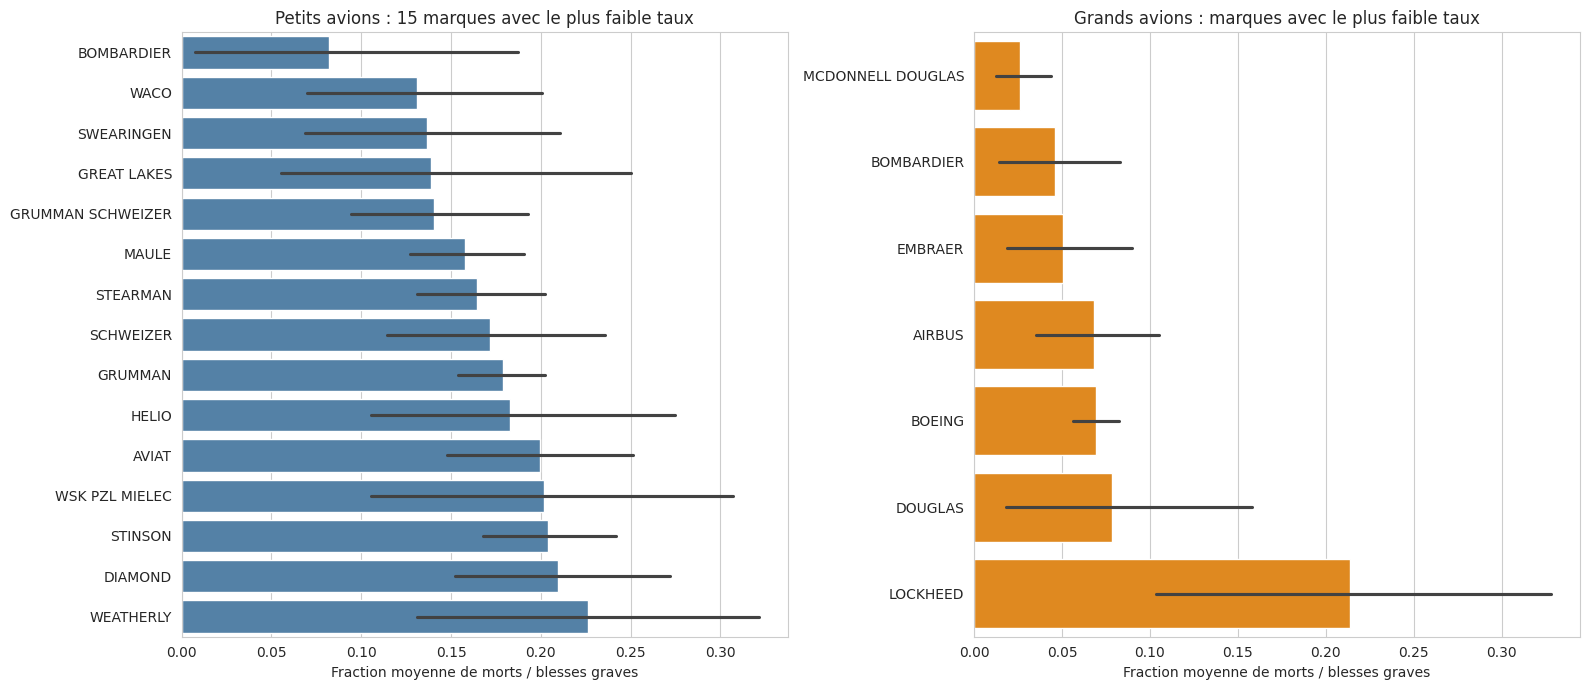

In [75]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(data=petits_df[petits_df["Make"].isin(top15_petits.index)],
            x="Fatal.Serious.Rate", y="Make", order=top15_petits.index,
            color="steelblue", ax=axes[0])
axes[0].set_title("Petits avions : 15 marques avec le plus faible taux")
axes[0].set_xlabel("Fraction moyenne de morts / blesses graves")
axes[0].set_ylabel("")

sns.barplot(data=grands_df[grands_df["Make"].isin(top15_grands.index)],
            x="Fatal.Serious.Rate", y="Make", order=top15_grands.index,
            color="darkorange", ax=axes[1])
axes[1].set_title("Grands avions : marques avec le plus faible taux")
axes[1].set_xlabel("Fraction moyenne de morts / blesses graves")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Note :**
- **Petits avions :** les premieres marques (Bombardier, Waco, Swearingen, Great Lakes) ont peu d'accidents (22 a 98), leurs intervalles de confiance sont larges. Maule (486 accidents, 0.158), Stearman (323, 0.165) et Grumman (924, 0.179) ont des intervalles beaucoup plus petits et sont nettement en dessous de la moyenne des petits avions (0.273), donc ces resultats sont plus fiables.
- Bombardier dans les petits avions ce sont des jets d'affaires (Challenger, Global) avec peu de monde a bord.
- **Grands avions :** il reste seulement 7 marques avec au moins 20 accidents. McDonnell Douglas a le taux le plus bas (2.6%), puis Bombardier (4.6%), Embraer (5.0%), Airbus (6.8%) et Boeing (7.0%). Les intervalles de confiance de ces marques se chevauchent, donc on ne peut pas dire qu'il y a une vraie difference entre elles. Lockheed (21.4%) est clairement moins bien.

**Distribution des taux de blessures : petites marques**

Utilisez un violinplot pour examiner la distribution de la fraction de passagers gravement/mortellement blessés pour les marques de petits avions. N'affichez que les marques ayant les dix taux moyens de blessures graves/mortelles les plus faibles.

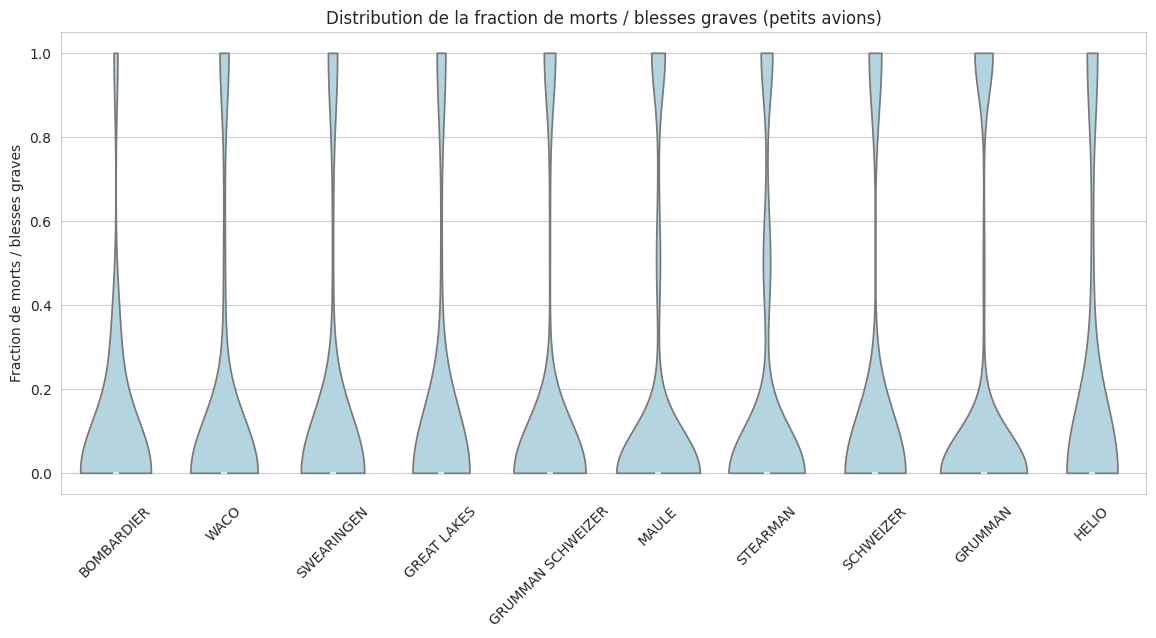

In [76]:
top10_petits = marques_petits.sort_values("taux_blesses_moyen").head(10).index

plt.figure(figsize=(14, 6))
sns.violinplot(data=petits_df[petits_df["Make"].isin(top10_petits)],
               x="Make", y="Fatal.Serious.Rate", order=top10_petits, cut=0, color="lightblue")
plt.title("Distribution de la fraction de morts / blesses graves (petits avions)")
plt.xlabel("")
plt.ylabel("Fraction de morts / blesses graves")
plt.xticks(rotation=45)
plt.show()

**Note :** les violons ont tous la meme forme : beaucoup d'accidents a 0 (personne de gravement touche), un autre groupe a 1 (tout le monde mort ou gravement blesse) et tres peu entre les deux. C'est logique, un petit avion a souvent 1 ou 2 personnes a bord, donc la fraction ne peut valoir que 0, 0.5 ou 1.

Donc la moyenne du taux ressemble beaucoup au pourcentage d'accidents graves. Une marque avec un taux de 0.16 (Maule) veut dire qu'environ 1 accident sur 6 fait des morts ou des blesses graves. Pour les meilleures marques la partie en bas (a 0) du violon est plus large que la partie en haut.

**Distribution des taux de blessures : grandes marques**

Utilisez un stripplot pour examiner la distribution de la fraction de passagers gravement/mortellement blessés pour les marques de grands avions. N'affichez que les marques ayant les dix taux moyens de blessures graves/mortelles les plus faibles.

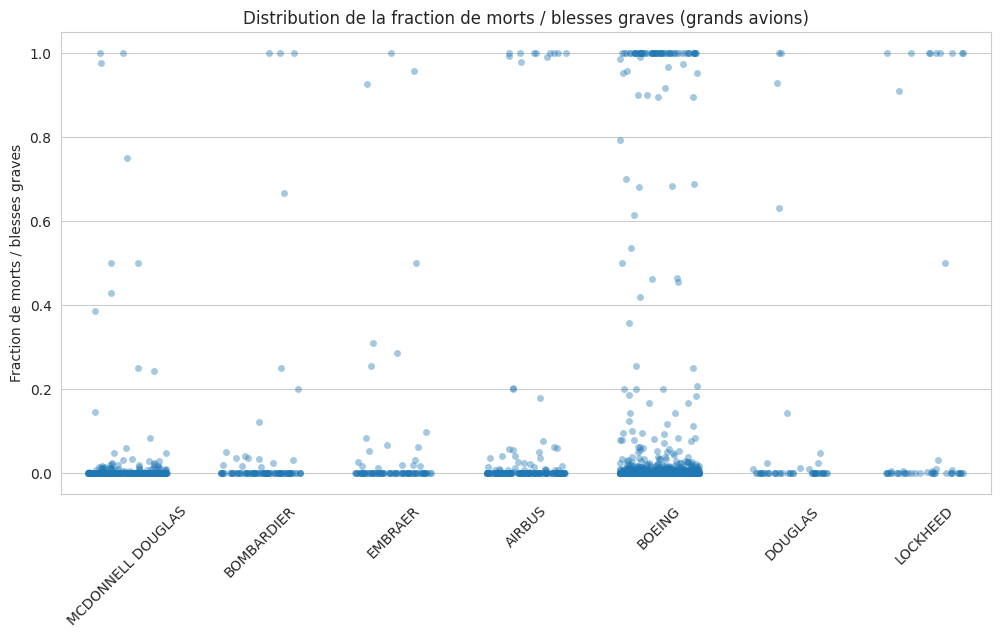

In [77]:
top10_grands = marques_grands.sort_values("taux_blesses_moyen").head(10).index

plt.figure(figsize=(12, 6))
sns.stripplot(data=grands_df[grands_df["Make"].isin(top10_grands)],
              x="Make", y="Fatal.Serious.Rate", order=top10_grands, alpha=0.4, jitter=0.3)
plt.title("Distribution de la fraction de morts / blesses graves (grands avions)")
plt.xlabel("")
plt.ylabel("Fraction de morts / blesses graves")
plt.xticks(rotation=45)
plt.show()

In [78]:
# pourcentage d'accidents sans aucun mort ni blesse grave, pour chaque grande marque
(1 - grands_df[grands_df["Make"].isin(top10_grands)].groupby("Make")["Severe.Accident"].mean()).sort_values(ascending=False).round(3)

,Severe.Accident
Make,
BOMBARDIER,0.828
EMBRAER,0.798
DOUGLAS,0.776
MCDONNELL DOUGLAS,0.772
AIRBUS,0.761
BOEING,0.730
LOCKHEED,0.633


**Note :** pour les grands avions presque tous les points sont colles a 0. Entre 73% (Boeing) et 83% (Bombardier) des accidents ne font aucun mort ni blesse grave. Quand il y a des victimes, c'est en general une petite fraction des passagers (points entre 0 et 0.1). Les points proches de 1 sont les gros crashs, il y en a tres peu mais ce sont eux qui font monter la moyenne. Lockheed a plus de points en haut, ce sont souvent des vieux avions (L-1011, Electra) ou des avions cargo.

**Évaluez le taux de destruction des appareils, petits et grands, par marque (Make).**

Triez vos résultats et conservez les 15 plus bas.

**Note :** pour le taux de destruction on utilise la colonne `Destroyed` (1 = detruit, 0 = pas detruit). La moyenne donne la proportion d'avions detruits. Les accidents avec des degats inconnus (NaN) ne sont pas comptes.

In [79]:
destr_petits = marques_petits.sort_values("taux_destruction").head(15)
destr_grands = marques_grands.sort_values("taux_destruction").head(15)

print("PETITS AVIONS")
print(destr_petits.round(3))
print("\nGRANDS AVIONS")
print(destr_grands.round(3))

PETITS AVIONS
                   nb_accidents  taux_blesses_moyen  taux_destruction
Make                                                                 
AVIAT                       223               0.200             0.063
DIAMOND                     158               0.210             0.064
BOMBARDIER                   22               0.082             0.067
FLIGHT DESIGN                79               0.354             0.076
STEARMAN                    323               0.165             0.078
MAULE                       486               0.158             0.088
AMERICAN CHAMPION            68               0.294             0.090
WACO                         98               0.131             0.093
LUSCOMBE                    366               0.232             0.099
TAYLORCRAFT                 327               0.300             0.110
GREAT LAKES                  54               0.139             0.111
SWEARINGEN                   84               0.137             0.117
AERONC

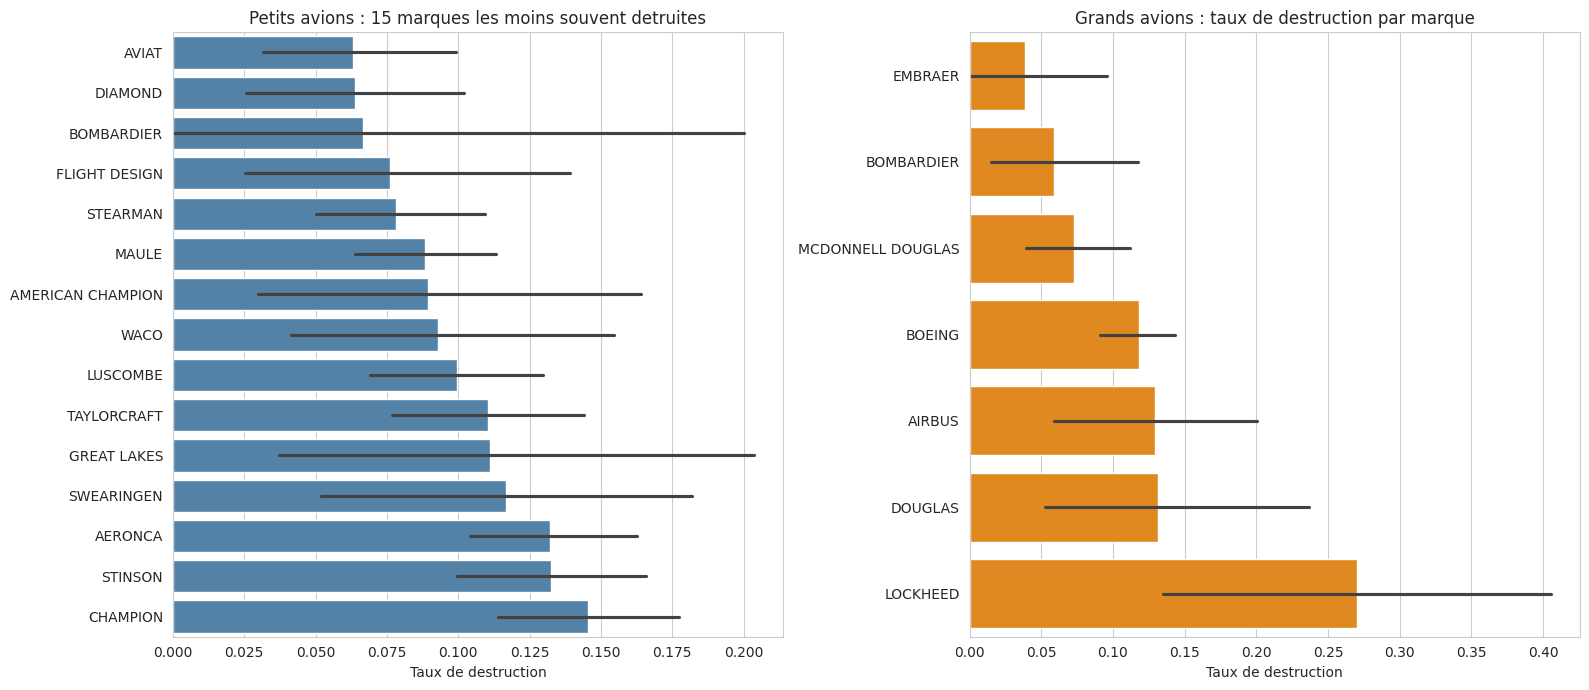

In [80]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(data=petits_df[petits_df["Make"].isin(destr_petits.index)],
            x="Destroyed", y="Make", order=destr_petits.index, color="steelblue", ax=axes[0])
axes[0].set_title("Petits avions : 15 marques les moins souvent detruites")
axes[0].set_xlabel("Taux de destruction")
axes[0].set_ylabel("")

sns.barplot(data=grands_df[grands_df["Make"].isin(destr_grands.index)],
            x="Destroyed", y="Make", order=destr_grands.index, color="darkorange", ax=axes[1])
axes[1].set_title("Grands avions : taux de destruction par marque")
axes[1].set_xlabel("Taux de destruction")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [81]:
# Marques bien placees sur les DEUX criteres (en dessous de la moyenne de leur groupe pour les deux)
for nom, marques, groupe in [("Petits", marques_petits, petits_df), ("Grands", marques_grands, grands_df)]:
    moy_blesses = groupe["Fatal.Serious.Rate"].mean()
    moy_destr = groupe["Destroyed"].mean()
    bonnes = marques[(marques["taux_blesses_moyen"] < moy_blesses) & (marques["taux_destruction"] < moy_destr)]
    print(f"{nom} avions (moyenne groupe : blesses {moy_blesses:.3f}, destruction {moy_destr:.3f})")
    print(bonnes.sort_values("taux_destruction").round(3), "\n")

Petits avions (moyenne groupe : blesses 0.273, destruction 0.206)
                   nb_accidents  taux_blesses_moyen  taux_destruction
Make                                                                 
AVIAT                       223               0.200             0.063
DIAMOND                     158               0.210             0.064
BOMBARDIER                   22               0.082             0.067
STEARMAN                    323               0.165             0.078
MAULE                       486               0.158             0.088
WACO                         98               0.131             0.093
LUSCOMBE                    366               0.232             0.099
GREAT LAKES                  54               0.139             0.111
SWEARINGEN                   84               0.137             0.117
AERONCA                     531               0.254             0.132
STINSON                     392               0.204             0.133
CHAMPION                

#### Rédigez une brève discussion de vos résultats concernant vos statistiques descriptives et vos graphiques :
- Formulez ici vos recommandations de marques (Makes) en vous basant sur la fraction d'appareils détruits et la fraction de blessés mortels/graves
- Commentez les statistiques calculées et les distributions correspondantes que vous avez visualisées.

**Discussion sur les marques**

Rappel : on mesure ce qui se passe **quand il y a un accident** (gravite), pas la probabilite d'avoir un accident. La base ne contient pas le nombre d'heures de vol, donc on ne peut pas dire qu'une marque a moins d'accidents qu'une autre.

**Petits avions**

Moyenne du groupe : 27.3% de morts/blesses graves et 20.6% d'avions detruits.

| Marque | Accidents | Morts/blesses graves | Detruits |
|---|---|---|---|
| Maule | 486 | 15.8% | 8.8% |
| Aviat | 223 | 20.0% | 6.3% |
| Diamond | 158 | 21.0% | 6.4% |
| Cessna | 24 851 | 24.1% | 18.7% |

Recommandations :
- **Maule, Aviat et Diamond** sont en dessous de la moyenne pour les deux criteres, avec assez d'accidents pour que ce soit fiable. Ce sont aussi des constructeurs qui fabriquent encore des avions. Diamond et Aviat ont les taux de destruction les plus bas de tout le groupe.
- **Cessna** est un peu en dessous de la moyenne pour les deux criteres. Son gros avantage c'est le nombre d'accidents (presque 25 000) : l'estimation est tres precise, il y a peu de risque de surprise pour un assureur.
- Stearman, Waco, Great Lakes et Luscombe ont aussi de bons chiffres, mais ce sont des avions anciens (biplans, avions des annees 1930 a 1950), ils ne correspondent pas vraiment a ce que cherche le client.
- A eviter : Mitsubishi (56.7% et 50.6%), Socata, Cirrus, Beech et Mooney sont au dessus de la moyenne.

**Grands avions**

Moyenne du groupe : 6.6% de morts/blesses graves et 10.9% d'avions detruits.

| Marque | Accidents | Morts/blesses graves | Detruits |
|---|---|---|---|
| Embraer | 94 | 5.0% | 3.8% |
| Bombardier | 99 | 4.6% | 5.9% |
| McDonnell Douglas | 268 | 2.6% | 7.3% |
| Boeing | 1 198 | 7.0% | 11.8% |
| Airbus | 180 | 6.8% | 12.9% |

Recommandations :
- **Embraer et Bombardier** (avions regionaux : Embraer ERJ, Bombardier CRJ) sont, avec McDonnell Douglas, les seules marques en dessous de la moyenne pour les deux criteres. Ce sont nos premieres recommandations pour les grands avions. Embraer fabrique encore ses avions. Bombardier a arrete les CRJ en 2020, mais beaucoup sont encore en service.
- **McDonnell Douglas** a le taux de blesses le plus bas mais la marque n'existe plus (rachetee par Boeing en 1997), ses avions sont de plus en plus retires.
- **Boeing et Airbus** sont proches de la moyenne. Les differences entre ces marques sont petites et les intervalles de confiance se chevauchent, donc on ne peut pas affirmer qu'une marque est vraiment meilleure qu'une autre.
- Lockheed est la moins bonne marque, mais ses avions de ligne ne sont plus en service.

### Analyser les types d'avions
- tracez la fraction moyenne de blessés mortels/graves pour les petits et les grands avions
- fournissez aussi un graphique de distribution de votre choix pour la fraction de blessés mortels/graves par type d'avion (stripplot, violin, etc.)  
- filtrez pour vous assurer de disposer d'au moins dix exemples individuels pour chaque modèle/marque sur lesquels calculer la moyenne

**Note :** pour les types d'avions on utilise la colonne `Make.Model` creee pendant le nettoyage (marque + modele). On garde seulement les types avec au moins 10 accidents, comme demande.

In [82]:
def stats_types(data, minimum=10):
    resultat = data.groupby("Make.Model").agg(
        nb_accidents=("Fatal.Serious.Rate", "count"),
        taux_blesses_moyen=("Fatal.Serious.Rate", "mean"),
        taux_destruction=("Destroyed", "mean"))
    return resultat[resultat["nb_accidents"] >= minimum]

types_petits = stats_types(petits_df)
types_grands = stats_types(grands_df)
print("Types petits avions :", len(types_petits))
print("Types grands avions :", len(types_grands))

Types petits avions : 648
Types grands avions : 53


**Grands avions**

In [83]:
top_types_grands = types_grands.sort_values("taux_blesses_moyen").head(15)
top_types_grands.round(4)

,nb_accidents,taux_blesses_moyen,taux_destruction
Make.Model,,,
MCDONNELL DOUGLAS MD11F,14,0.0000,0.0909
MCDONNELL DOUGLAS MD83,20,0.0010,0.0714
BOEING 717200,16,0.0013,0.0000
BOEING 7373H4,14,0.0020,0.0000
BOEING 747422,12,0.0022,0.0000
BOEING 757223,17,0.0024,0.0000
BOEING 787,12,0.0028,0.0000
MCDONNELL DOUGLAS DC10,10,0.0028,0.0000
MCDONNELL DOUGLAS MD88,34,0.0028,0.0000


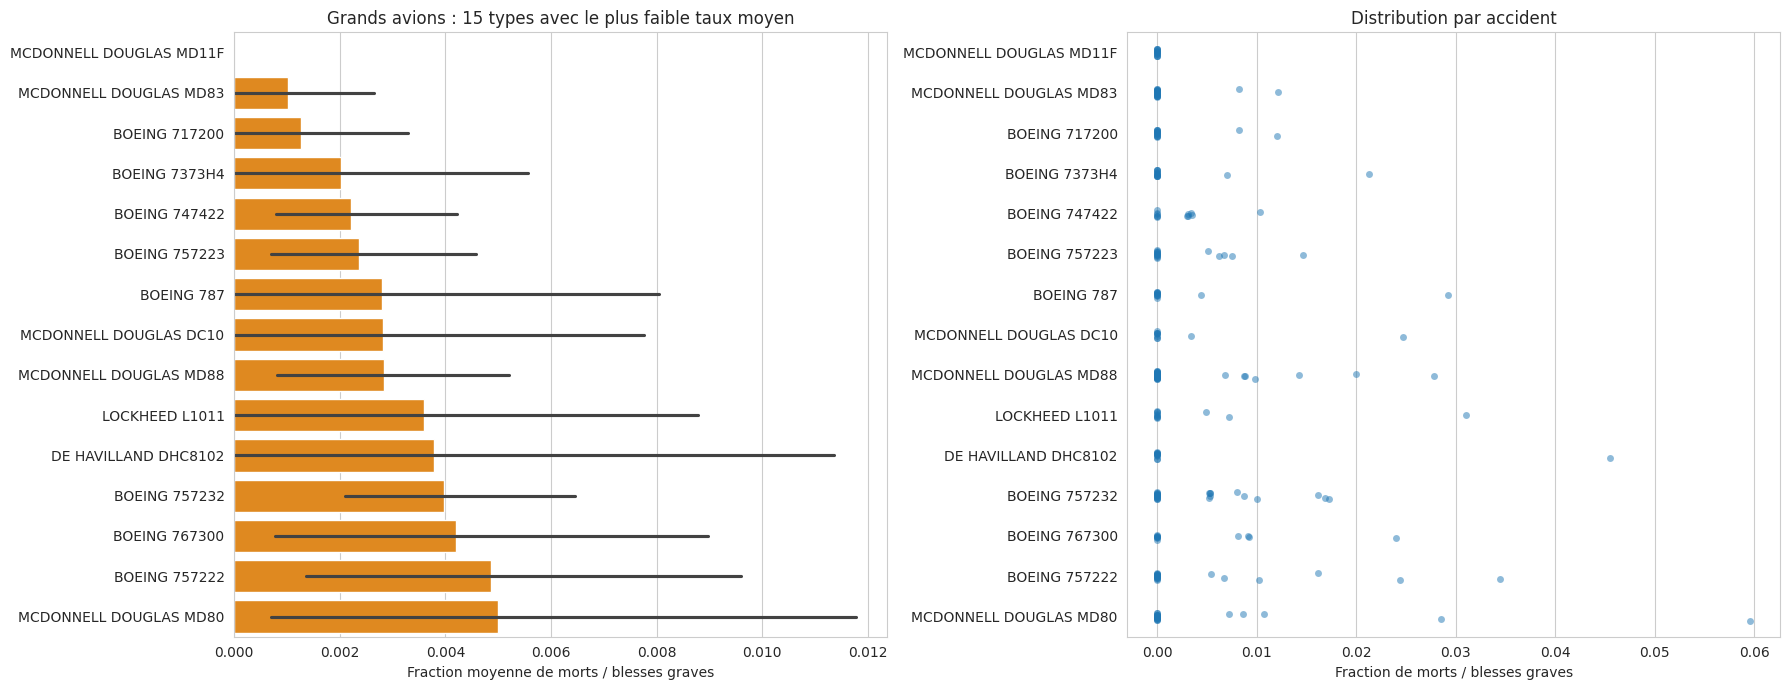

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

data_g = grands_df[grands_df["Make.Model"].isin(top_types_grands.index)]

sns.barplot(data=data_g, x="Fatal.Serious.Rate", y="Make.Model",
            order=top_types_grands.index, color="darkorange", ax=axes[0])
axes[0].set_title("Grands avions : 15 types avec le plus faible taux moyen")
axes[0].set_xlabel("Fraction moyenne de morts / blesses graves")
axes[0].set_ylabel("")

sns.stripplot(data=data_g, x="Fatal.Serious.Rate", y="Make.Model",
              order=top_types_grands.index, alpha=0.5, ax=axes[1])
axes[1].set_title("Distribution par accident")
axes[1].set_xlabel("Fraction de morts / blesses graves")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [85]:
# Tous les grands types (au moins 10 accidents) : combien ont un taux moyen presque nul ?
print("Types avec taux moyen < 1% :", (types_grands["taux_blesses_moyen"] < 0.01).sum(), "sur", len(types_grands))
print("\nTypes les moins souvent detruits :")
print(types_grands.sort_values(["taux_destruction", "taux_blesses_moyen"]).head(10).round(4))
print("\nTypes les plus mal places :")
print(types_grands.sort_values("taux_blesses_moyen", ascending=False).head(5).round(3))

Types avec taux moyen < 1% : 19 sur 53

Types les moins souvent detruits :
                        nb_accidents  taux_blesses_moyen  taux_destruction
Make.Model                                                                
BOEING 717200                     16              0.0013               0.0
BOEING 7373H4                     14              0.0020               0.0
BOEING 747422                     12              0.0022               0.0
BOEING 757223                     17              0.0024               0.0
BOEING 787                        12              0.0028               0.0
MCDONNELL DOUGLAS DC10            10              0.0028               0.0
MCDONNELL DOUGLAS MD88            34              0.0028               0.0
LOCKHEED L1011                    12              0.0036               0.0
DE HAVILLAND DHC8102              12              0.0038               0.0
BOEING 757232                     26              0.0040               0.0

Types les plus mal place

**Petits avions**
- pour les petits avions, limitez les résultats tracés aux marques ayant les 10 fractions moyennes de blessés graves/mortels les plus faibles

In [86]:
top_types_petits = types_petits.sort_values("taux_blesses_moyen").head(10)
top_types_petits.round(3)

,nb_accidents,taux_blesses_moyen,taux_destruction
Make.Model,,,
CESSNA 180C,15,0.000,0.067
MAULE MX7235,22,0.023,0.000
MAULE M4,26,0.038,0.038
CESSNA 560XL,25,0.040,0.125
DIAMOND DA42,12,0.042,0.000
CESSNA C172,12,0.042,0.000
NORTH AMERICAN AT6G,11,0.045,0.000
CESSNA L19,11,0.045,0.091
PIPER PA18160,32,0.047,0.031


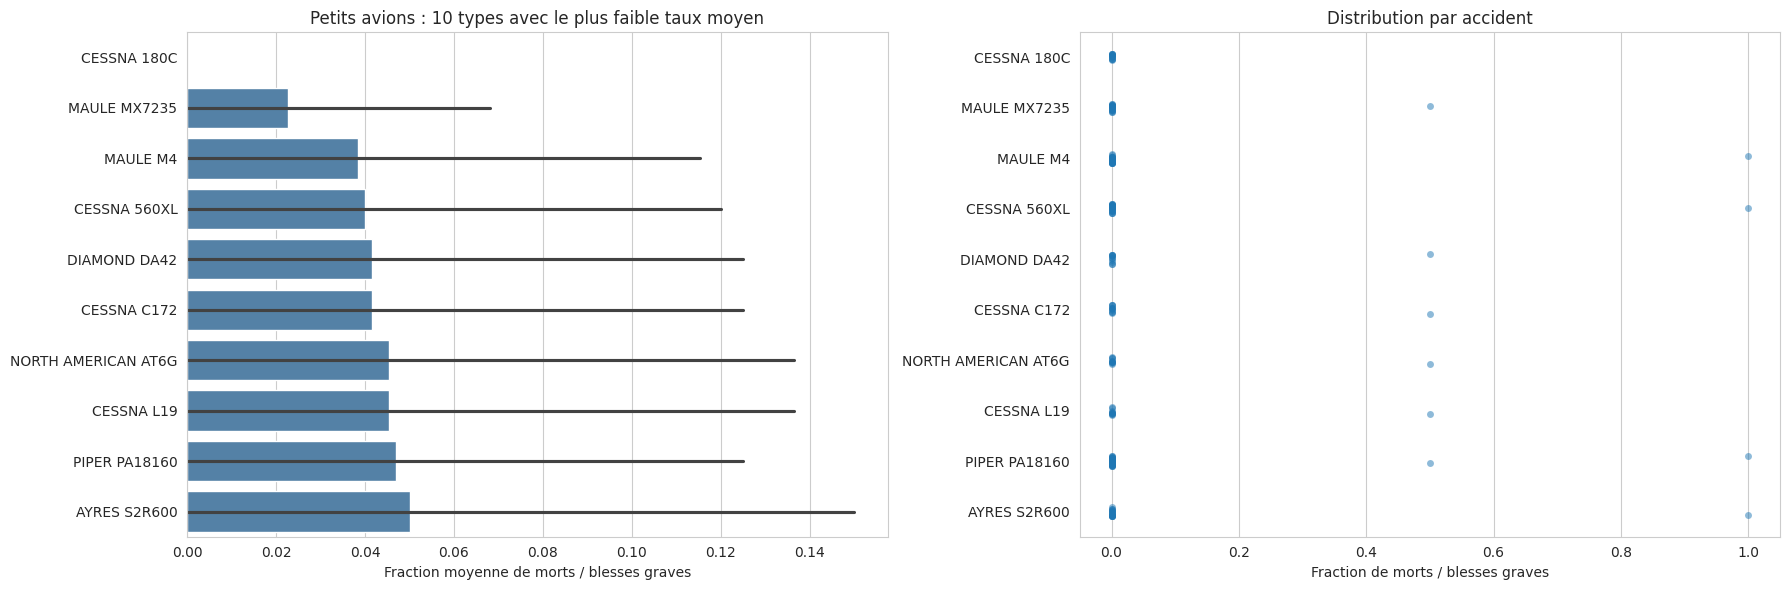

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

data_p = petits_df[petits_df["Make.Model"].isin(top_types_petits.index)]

sns.barplot(data=data_p, x="Fatal.Serious.Rate", y="Make.Model",
            order=top_types_petits.index, color="steelblue", ax=axes[0])
axes[0].set_title("Petits avions : 10 types avec le plus faible taux moyen")
axes[0].set_xlabel("Fraction moyenne de morts / blesses graves")
axes[0].set_ylabel("")

sns.stripplot(data=data_p, x="Fatal.Serious.Rate", y="Make.Model",
              order=top_types_petits.index, alpha=0.5, ax=axes[1])
axes[1].set_title("Distribution par accident")
axes[1].set_xlabel("Fraction de morts / blesses graves")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Note :** les 10 meilleurs types ont souvent entre 10 et 30 accidents seulement, donc les intervalles de confiance sont tres larges. Pour avoir des resultats plus fiables, on refait le classement avec seulement les types qui ont **au moins 100 accidents**.

Types avec au moins 100 accidents : 121
               nb_accidents  taux_blesses_moyen  taux_destruction
Make.Model                                                       
PIPER PA20              132               0.080             0.053
CESSNA 185F             100               0.088             0.091
CESSNA 180              593               0.112             0.076
CESSNA 170              151               0.121             0.086
CESSNA 185              265               0.123             0.099
GRUMMAN G164B           195               0.125             0.253
GRUMMAN G164A           355               0.127             0.225
CESSNA 170B             379               0.137             0.084
CESSNA 172R             171               0.154             0.071
PIPER PA18              661               0.155             0.080


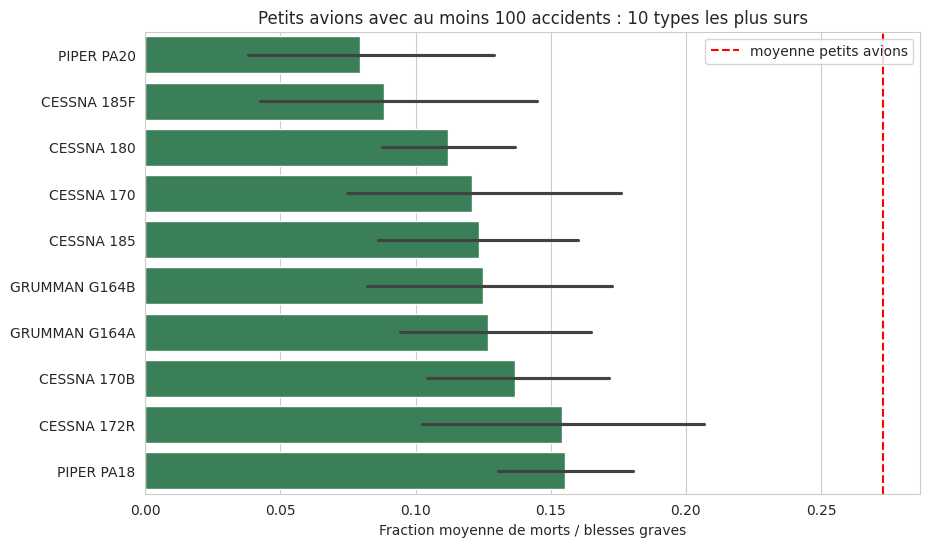

In [88]:
types_petits_100 = stats_types(petits_df, minimum=100)
print("Types avec au moins 100 accidents :", len(types_petits_100))

top_100 = types_petits_100.sort_values("taux_blesses_moyen").head(10)
print(top_100.round(3))

plt.figure(figsize=(10, 6))
sns.barplot(data=petits_df[petits_df["Make.Model"].isin(top_100.index)],
            x="Fatal.Serious.Rate", y="Make.Model", order=top_100.index, color="seagreen")
plt.axvline(petits_df["Fatal.Serious.Rate"].mean(), color="red", linestyle="--", label="moyenne petits avions")
plt.title("Petits avions avec au moins 100 accidents : 10 types les plus surs")
plt.xlabel("Fraction moyenne de morts / blesses graves")
plt.ylabel("")
plt.legend()
plt.show()

In [89]:
# et pour la destruction
types_petits_100.sort_values("taux_destruction").head(10).round(3)

,nb_accidents,taux_blesses_moyen,taux_destruction
Make.Model,,,
PIPER PA20,132,0.080,0.053
CESSNA 172S,372,0.167,0.069
CESSNA 140,384,0.167,0.070
CESSNA 172R,171,0.154,0.071
STEARMAN A75N1,113,0.177,0.071
CESSNA 180,593,0.112,0.076
PIPER PA18,661,0.155,0.080
CESSNA 170B,379,0.137,0.084
CESSNA 170,151,0.121,0.086


### Discussion sur les types d'avions spécifiques
- Discutez de ce que vous avez trouvé ci-dessus concernant la fraction de passagers gravement blessés pour les modèles de petits et de grands avions.

**Discussion sur les types d'avions**

**Grands avions**
- Pour la plupart des grands types, le taux de morts/blesses graves est tres faible : 19 types sur 53 ont un taux moyen en dessous de 1%.
- Plusieurs types n'ont jamais ete detruits dans leurs accidents : Boeing 717, 757, 787, 747-400, MD-88. Ce sont des avions recents ou encore tres utilises, ils sont de bons candidats pour le client.
- Les types les moins bien places sont le **Boeing 737-200** (23.6% de blesses, 42% detruits), le 737-400 et certains Airbus A320/A321. Le 737-200 est un ancien modele. Pour les Airbus, il y a peu d'accidents (11 a 29), donc quelques gros crashs suffisent a faire monter la moyenne.
- Limite : les noms de modeles sont souvent tres detailles (par exemple "757223" et "757232" sont deux versions du 757 pour des compagnies differentes). Les accidents d'un meme avion sont donc partages entre plusieurs lignes, et chaque ligne a peu d'accidents.

**Petits avions**
- Les 10 meilleurs types avec au moins 10 accidents (Cessna 180C, Maule MX-7-235, Diamond DA42...) ont tres peu d'accidents (10 a 32), donc ce classement n'est pas tres fiable.
- Avec au moins 100 accidents le classement est plus solide. Les meilleurs types sont le **Piper PA-20** (8% de blesses, 5.3% detruits), les **Cessna 180, 185 et 170** (11 a 14% de blesses, moins de 10% detruits) et le **Piper PA-18** (15.5%, 8%).
- Les **Cessna 172R et 172S** sont tres interessants pour le client : ce sont les versions recentes du 172 (le 172S est encore fabrique), avec environ 16% de blesses (moyenne du groupe : 27%) et environ 7% d'avions detruits (moyenne : 21%).
- Les Grumman G-164 (avions agricoles) ont peu de blesses mais sont souvent detruits (22 a 25%) : mauvais pour un assureur qui paie l'avion.

### Explorer d'autres variables
- Étudiez l'effet d'autres variables sur les dommages aux appareils et les blessures. Vous devez choisir **deux** facteurs parmi les suivants, mais vous êtes libre d'en analyser davantage :

- Conditions météorologiques
- Type de moteur
- Nombre de moteurs
- Phase de vol
- Objet du vol

Pour chaque facteur, rédigez une discussion expliquant votre analyse avec des visualisations / résumés de données appropriés et en interprétant vos résultats.

On etudie **trois facteurs** : les conditions meteo, le nombre de moteurs et la phase de vol.

Pour chaque facteur on regarde :
- un tableau avec le nombre d'accidents, le taux moyen de morts/blesses graves et le taux de destruction ;
- des graphiques avec intervalles de confiance ;


#### Facteur 1 : conditions meteo

- **VMC** : bonne visibilite, le pilote vole a vue.
- **IMC** : mauvaise visibilite (nuages, brouillard), le pilote doit voler aux instruments.

On enleve les accidents avec meteo inconnue.

In [90]:
meteo_df = aviation_df[aviation_df["Weather.Condition"] != "UNKNOWN"]

meteo_df.groupby("Weather.Condition").agg(
    nb_accidents=("Fatal.Serious.Rate", "count"),
    taux_blesses_moyen=("Fatal.Serious.Rate", "mean"),
    pct_accidents_graves=("Severe.Accident", "mean"),
    taux_destruction=("Destroyed", "mean")).round(3)

,nb_accidents,taux_blesses_moyen,pct_accidents_graves,taux_destruction
Weather.Condition,,,,
IMC,4395,0.663,0.709,0.587
VMC,49420,0.219,0.254,0.162


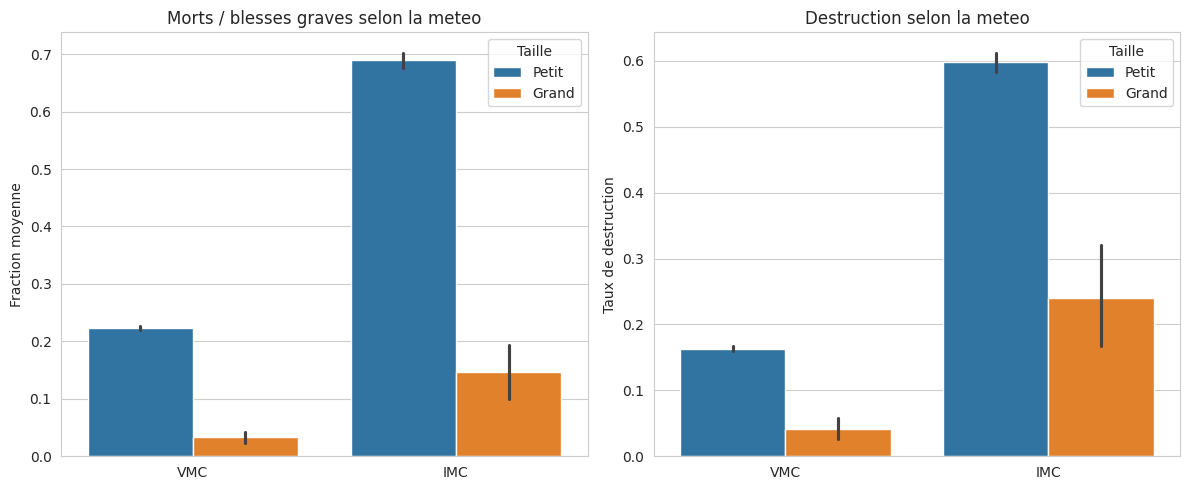

In [91]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(data=meteo_df, x="Weather.Condition", y="Fatal.Serious.Rate", hue="Taille", ax=axes[0])
axes[0].set_title("Morts / blesses graves selon la meteo")
axes[0].set_ylabel("Fraction moyenne")
axes[0].set_xlabel("")

sns.barplot(data=meteo_df, x="Weather.Condition", y="Destroyed", hue="Taille", ax=axes[1])
axes[1].set_title("Destruction selon la meteo")
axes[1].set_ylabel("Taux de destruction")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()

**Discussion : meteo**

- Quand l'accident se passe en **IMC** (mauvaise visibilite), la fraction moyenne de morts/blesses graves est de **66.3%**, contre **21.9%** en VMC, c'est 3 fois plus.
- L'avion est detruit dans **58.7%** des accidents en IMC contre **16.2%** en VMC.
- Le graphique montre que c'est vrai pour les petits et pour les grands avions.

Explication possible : par beau temps, beaucoup d'accidents sont des petits incidents a l'atterrissage a faible vitesse. Par mauvais temps, le pilote ne voit pas le sol et les accidents sont plus souvent des pertes de controle ou des collisions avec le relief, a grande vitesse.

Pour le client : les vols par mauvais temps sont beaucoup plus risques. Il pourrait tenir compte de la qualification de vol aux instruments des pilotes et du type d'utilisation de l'avion.

#### Facteur 2 : nombre de moteurs

Les avions a 3 ou 4 moteurs sont tous dans le groupe "Grand". Pour comparer des choses comparables, on etudie surtout les **petits avions** : 1 moteur contre 2 moteurs.

In [92]:
petits_df.groupby("Number.of.Engines").agg(
    nb_accidents=("Fatal.Serious.Rate", "count"),
    taux_blesses_moyen=("Fatal.Serious.Rate", "mean"),
    pct_accidents_graves=("Severe.Accident", "mean"),
    taux_destruction=("Destroyed", "mean")).round(3)

,nb_accidents,taux_blesses_moyen,pct_accidents_graves,taux_destruction
Number.of.Engines,,,,
1,47739,0.260,0.291,0.189
2,6877,0.367,0.403,0.327


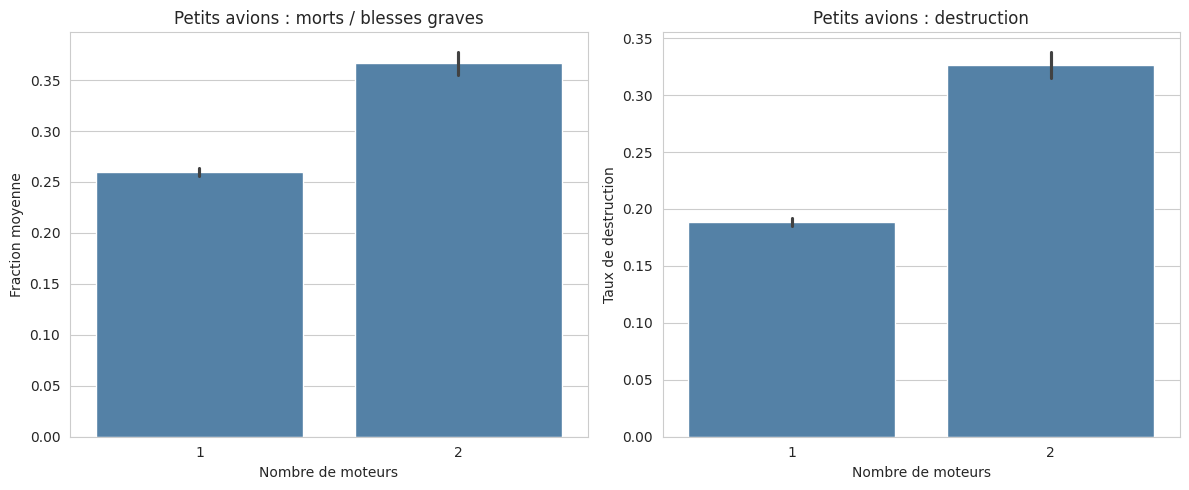

In [93]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(data=petits_df, x="Number.of.Engines", y="Fatal.Serious.Rate", color="steelblue", ax=axes[0])
axes[0].set_title("Petits avions : morts / blesses graves")
axes[0].set_xlabel("Nombre de moteurs")
axes[0].set_ylabel("Fraction moyenne")

sns.barplot(data=petits_df, x="Number.of.Engines", y="Destroyed", color="steelblue", ax=axes[1])
axes[1].set_title("Petits avions : destruction")
axes[1].set_xlabel("Nombre de moteurs")
axes[1].set_ylabel("Taux de destruction")

plt.tight_layout()
plt.show()

**Note :** on se demande si les bimoteurs ont des accidents plus graves juste parce qu'ils volent plus souvent par mauvais temps. On verifie : pourcentage de vols IMC pour chaque nombre de moteurs, puis le taux en VMC seulement.

In [94]:
# part de chaque meteo selon le nombre de moteurs
print(pd.crosstab(petits_df["Number.of.Engines"], petits_df["Weather.Condition"], normalize="index").round(3))

# taux de morts / blesses graves selon moteurs ET meteo
petits_df.pivot_table(index="Number.of.Engines", columns="Weather.Condition",
                      values="Fatal.Serious.Rate", aggfunc="mean").round(3)

Weather.Condition    IMC  UNKNOWN    VMC
Number.of.Engines                       
1                  0.061    0.032  0.907
2                  0.182    0.079  0.739


Weather.Condition,IMC,UNKNOWN,VMC
Number.of.Engines,,,
1,0.724,0.636,0.215
2,0.607,0.540,0.289


**Discussion : nombre de moteurs (petits avions)**

- Les bimoteurs ont des accidents plus graves que les monomoteurs : **36.7%** de morts/blesses graves contre **26.0%**, et **32.7%** d'avions detruits contre **18.9%**.
- Une partie de l'ecart vient de la meteo : 18.2% des accidents de bimoteurs sont en IMC, contre 6.1% pour les monomoteurs.
- Mais meme en VMC seulement, les bimoteurs restent moins bons (28.9% contre 21.5%). Par contre en IMC c'est l'inverse (60.7% contre 72.4%).

Explication possible : un bimoteur vole plus vite et est plus lourd, donc un accident fait plus de degats. Aussi, si un moteur tombe en panne, l'avion devient difficile a controler.

Pour le client : avoir deux moteurs ne rend pas un petit avion plus sur en cas d'accident, au contraire. Attention, on ne sait pas si les bimoteurs ont moins d'accidents par heure de vol, la base ne donne pas cette information.

#### Facteur 3 : phase de vol

Pendant le nettoyage on a vu que la phase de vol n'est plus remplie a partir de 2008. On utilise donc seulement les accidents de 1983 a 2007, et on enleve UNKNOWN et OTHER.

In [95]:
phase_df = aviation_df[(aviation_df["Event.Date"].dt.year < 2008) &
                       (~aviation_df["Broad.phase.of.flight"].isin(["UNKNOWN", "OTHER"]))]
print("Accidents utilises :", len(phase_df))

stats_phase = phase_df.groupby("Broad.phase.of.flight").agg(
    nb_accidents=("Fatal.Serious.Rate", "count"),
    taux_blesses_moyen=("Fatal.Serious.Rate", "mean"),
    taux_destruction=("Destroyed", "mean")).sort_values("taux_blesses_moyen")
stats_phase.round(3)

Accidents utilises : 39681


,nb_accidents,taux_blesses_moyen,taux_destruction
Broad.phase.of.flight,,,
TAXI,1358,0.019,0.019
LANDING,11001,0.035,0.042
STANDING,540,0.148,0.121
TAKEOFF,8119,0.223,0.214
GO-AROUND,1095,0.297,0.284
DESCENT,1218,0.326,0.328
APPROACH,4162,0.344,0.294
CRUISE,6661,0.344,0.340
CLIMB,1308,0.412,0.428


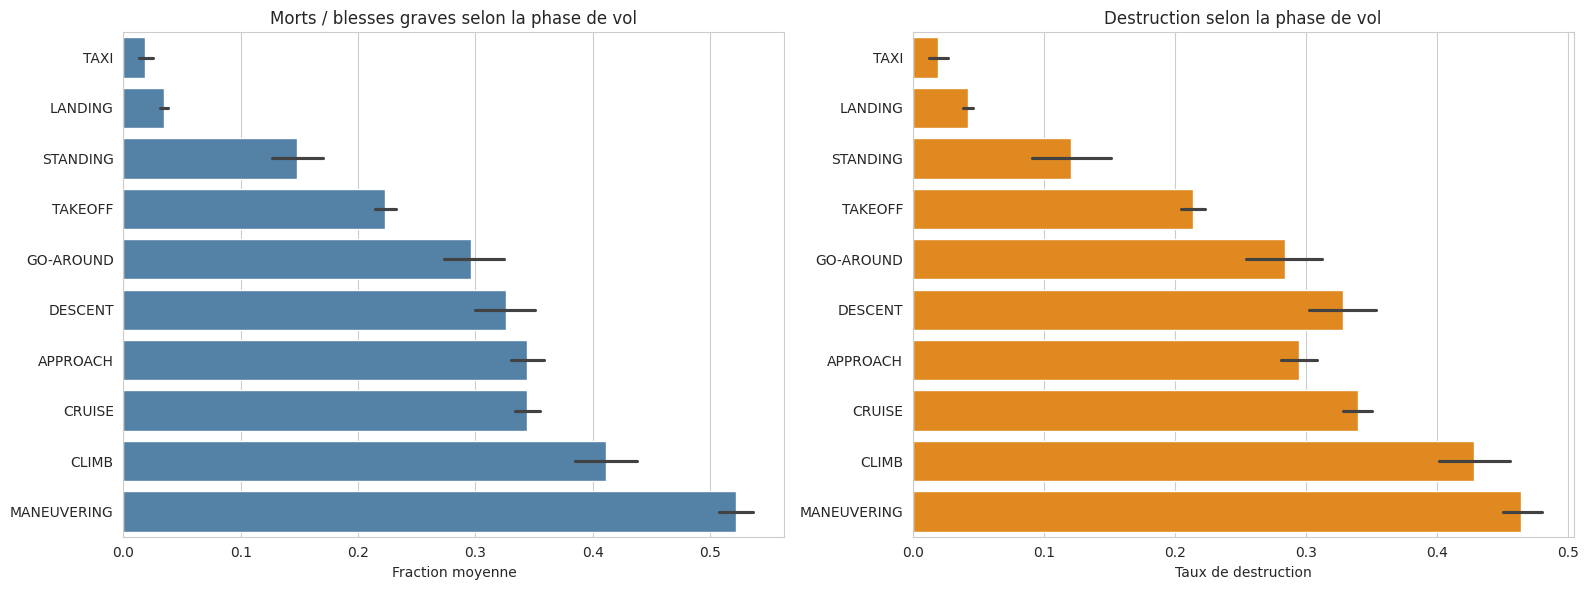

In [96]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=phase_df, x="Fatal.Serious.Rate", y="Broad.phase.of.flight",
            order=stats_phase.index, color="steelblue", ax=axes[0])
axes[0].set_title("Morts / blesses graves selon la phase de vol")
axes[0].set_xlabel("Fraction moyenne")
axes[0].set_ylabel("")

sns.barplot(data=phase_df, x="Destroyed", y="Broad.phase.of.flight",
            order=stats_phase.index, color="darkorange", ax=axes[1])
axes[1].set_title("Destruction selon la phase de vol")
axes[1].set_xlabel("Taux de destruction")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Discussion : phase de vol (1983 a 2007)**

- Les accidents au **roulage** (TAXI : 1.9%) et a l'**atterrissage** (LANDING : 3.5%) sont les moins graves et l'avion est rarement detruit (moins de 5%). L'avion va lentement et il est pres du sol.
- L'atterrissage est la phase avec le plus d'accidents (11 001), mais ce sont surtout des petits accidents.
- Les phases les plus dangereuses sont les **manoeuvres** (MANEUVERING : 52.2% de morts/blesses graves, 46.4% detruits), la **montee** (41.2%), la **croisiere** et l'**approche** (34.4%).


Pour le client : les accidents a l'atterrissage sont frequents mais coutent peu cher en blesses. Les vols avec beaucoup de manoeuvres a basse altitude (epandage agricole, voltige, ecole) sont plus risques.

Limite : les donnees de phase de vol s'arretent en 2007.

### Conclusion et recommandations

**Petits avions (20 personnes ou moins)**
- Marques : **Maule, Aviat et Diamond** (en dessous de la moyenne pour les blesses et la destruction), et **Cessna** (un peu en dessous de la moyenne, mais l'estimation la plus fiable grace au grand nombre d'accidents).
- Modeles : **Cessna 172R / 172S**, **Cessna 180 / 185**, **Piper PA-18**.
- A eviter : Mitsubishi, Socata, Cirrus, Mooney et Beech, qui sont au dessus de la moyenne.

**Grands avions (plus de 20 personnes)**
- Marques : **Embraer et Bombardier** (avions regionaux), en dessous de la moyenne pour les deux criteres. Boeing et Airbus sont proches de la moyenne, avec des differences pas significatives.
- Modeles : **Boeing 787, 757, 717 et 747-400** (jamais detruits dans les accidents de la base, mais avec seulement 12 a 26 accidents chacun, donc a confirmer). Eviter les vieux 737-200.

**Facteurs qui jouent sur la gravite**
1. **Meteo** : en IMC un accident est 3 fois plus grave et l'avion est detruit 3.6 fois plus souvent.
2. **Nombre de moteurs** : pour les petits avions, les accidents de bimoteurs sont plus graves que ceux des monomoteurs, meme par beau temps.
3. **Phase de vol** : les manoeuvres, la montee et la croisiere sont les phases les plus graves, l'atterrissage et le roulage les moins graves.

**Limites**
- On mesure la gravite d'un accident, pas le risque d'avoir un accident (pas d'heures de vol dans la base).
- Les valeurs manquantes de blessures ont ete remplacees par 0. On a verifie que c'etait justifie, mais quand le nombre d'indemnes manquait, le taux est peut-etre un peu surestime.
- Certaines marques et certains types ont peu d'accidents, il faut regarder les intervalles de confiance avant de conclure.